# Structural Steel MFA 1931-2100

## Imports

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from odym import dynamic_stock_model as dsm
from scipy import stats
from scipy.interpolate import interp1d
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from scipy.optimize import curve_fit
import weibull
from scipy.stats import linregress 
import matplotlib.lines as mlines
import matplotlib.ticker as mtick
from matplotlib.ticker import PercentFormatter
import plotly.graph_objects as go

c:\Users\aorga\Lib\site-packages\weibull\__init__.py:9: UserWarning: The "weibull" module is being superceded by the "reliability" module and will no longer be maintained. Please refactor your code for this alternative model and thank you for using weibull!
  warnings.warn('The "weibull" module is being superceded by the "reliability" module and will no longer be maintained. '


## Read in Data

In [3]:
df_population = pd.read_csv(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data_population.csv", index_col=0)
df_gdp = pd.read_csv(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data_GDP.csv", index_col=0)
# df_floorspace = pd.read_excel(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Jay MFA Code\Bldg_Stock-master\InputData\2016_01_10 Levesque FS per capita.xlsx', skiprows=7, index_col=0)
df_gdp_SSP2 = pd.read_excel(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Jay MFA Code\Bldg_Stock-master\InputData\Pop_Data.xlsx', sheet_name='GDP_pc', index_col=0)
df_steel = pd.read_csv(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data_production.csv', index_col=0)
df_energy_use = pd.read_excel(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\final_energy_use.xlsx", index_col=0)

df_steel_forecast = pd.read_csv(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\steel_forecast.csv", index_col=0) / 1e3

In [31]:
df_population

,pop_ssp1,pop_ssp2,pop_ssp3,pop_ssp4,pop_ssp5,Source
1931,124039648.0,124039648.0,124039648.0,124039648.0,124039648.0,U.S. Censusu Bureau
1932,124840471.0,124840471.0,124840471.0,124840471.0,124840471.0,U.S. Censusu Bureau
1933,125578763.0,125578763.0,125578763.0,125578763.0,125578763.0,U.S. Censusu Bureau
1934,126373773.0,126373773.0,126373773.0,126373773.0,126373773.0,U.S. Censusu Bureau
1935,127250232.0,127250232.0,127250232.0,127250232.0,127250232.0,U.S. Censusu Bureau
...,...,...,...,...,...,...
2080,392501973.0,404260551.0,420497001.0,348010415.0,448127860.0,IIASA
2085,392186330.0,406044541.0,429693201.0,341897990.0,450578954.0,IIASA
2090,390155587.0,406645230.0,439152913.0,334254837.0,450632128.0,IIASA
2095,386290251.0,406411009.0,449283549.0,325383215.0,448101727.0,IIASA


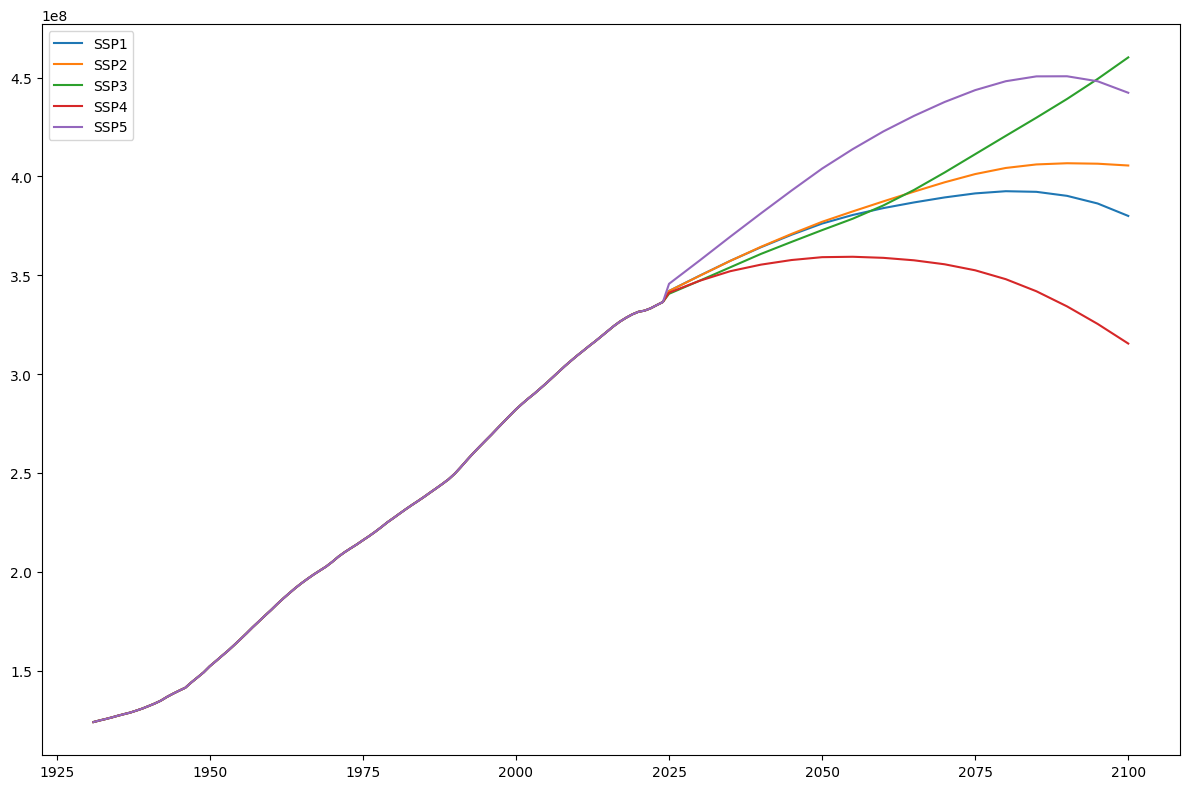

In [36]:
plt.plot(df_population.index,df_population['pop_ssp1'], label='SSP1')
plt.plot(df_population.index,df_population['pop_ssp2'], label='SSP2')
plt.plot(df_population.index,df_population['pop_ssp3'], label='SSP3')
plt.plot(df_population.index,df_population['pop_ssp4'], label='SSP4')
plt.plot(df_population.index,df_population['pop_ssp5'], label='SSP5')
plt.legend()

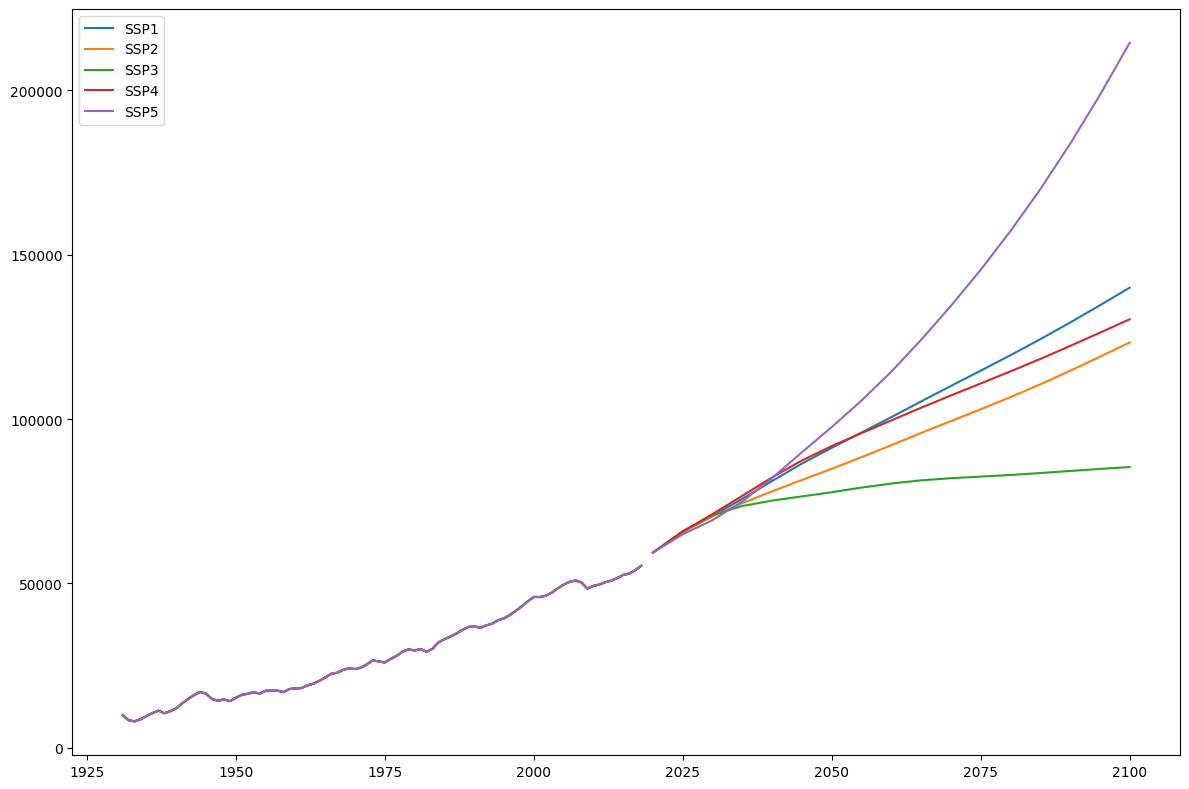

In [38]:
plt.plot(df_gdp.index,df_gdp['gdp_ssp1'], label='SSP1')
plt.plot(df_gdp.index,df_gdp['gdp_ssp2'], label='SSP2')
plt.plot(df_gdp.index,df_gdp['gdp_ssp3'], label='SSP3')
plt.plot(df_gdp.index,df_gdp['gdp_ssp4'], label='SSP4')
plt.plot(df_gdp.index,df_gdp['gdp_ssp5'], label='SSP5')
plt.legend()

## Perform MFA

In [4]:
## Define survival Function
def generate_lt(type, par1, par2):
    ''' Normal: par1  = mean, par2 = std. dev
        Weibull: par1 = shape, par2 = scale'''
    if type=='Normal':
        # Normal
        lt = {'Type': type, 'Mean': np.array([par1] * len(years)), 'StdDev': par2}
    elif type=='Weibull':
        # Weibull 
            lt = {'Type': type, 'Shape': np.array([par1]), 'Scale': np.array([par2])}
    return lt   

# For testing shapes
x=np.arange(1,170)
def weib(x,n,a):
    return (a/n) * (x/n)**(a-1) * np.exp(-(x/n)**a)

Text(0.5, 0, 'Age to Failuire')

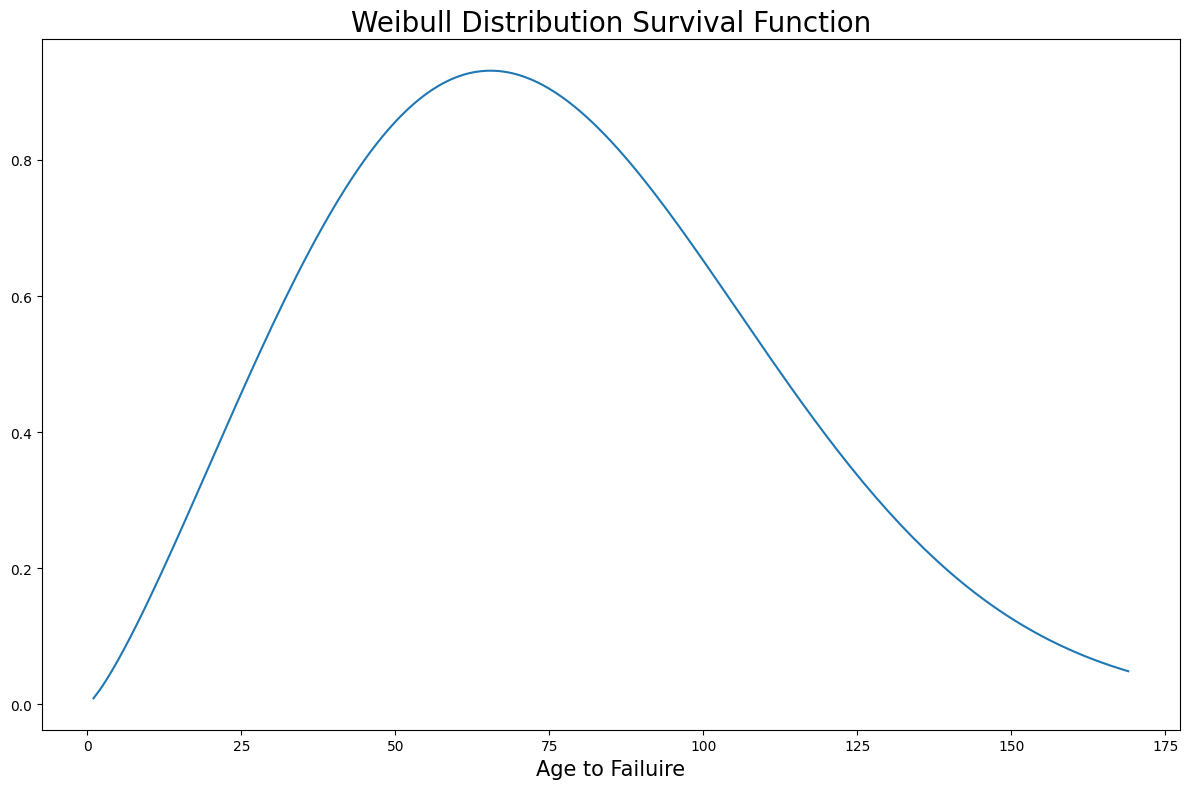

In [6]:
## See weibull shapes
lt_buildings = generate_lt('Weibull',par1=2.25,par2=85)

plt.plot(x, weib(x, lt_buildings['Scale'][0], lt_buildings['Shape'][0])*lt_buildings['Scale'][0])
plt.title('Weibull Distribution Survival Function', fontsize = 20)
plt.xlabel('Age to Failuire', fontsize = 15)

In [7]:
## Perform MFA ssp1
years = df_steel_forecast.index

steel_DSM_ssp1 = dsm.DynamicStockModel(t = np.array(years), i = np.array(df_steel_forecast['ssp1']), 
                                  lt = {'Type': 'Weibull', 'Shape': np.array([2.25]), 
                                        'Scale': np.array([85]) })

In [8]:
## Define aspects of MFA
stock_by_cohort =  steel_DSM_ssp1.compute_s_c_inflow_driven()
CheckStr = steel_DSM_ssp1.dimension_check()
S_steel = steel_DSM_ssp1.compute_stock_total() 
O_C = steel_DSM_ssp1.compute_o_c_from_s_c()
DS_steel = steel_DSM_ssp1.compute_stock_change()
O_steel = steel_DSM_ssp1.compute_outflow_total()

In [9]:
## Perform MFA ssp2

steel_DSM_ssp2 = dsm.DynamicStockModel(t = np.array(years), i = np.array(df_steel_forecast['ssp2']), 
                                  lt = {'Type': 'Weibull', 'Shape': np.array([2.25]), 
                                        'Scale': np.array([85]) })

stock_by_cohort =  steel_DSM_ssp2.compute_s_c_inflow_driven()
CheckStr = steel_DSM_ssp2.dimension_check()
S_steel = steel_DSM_ssp2.compute_stock_total() 
O_C = steel_DSM_ssp2.compute_o_c_from_s_c()
DS_steel = steel_DSM_ssp2.compute_stock_change()
O_steel = steel_DSM_ssp2.compute_outflow_total()

In [10]:
## Perform MFA ssp3

steel_DSM_ssp3 = dsm.DynamicStockModel(t = np.array(years), i = np.array(df_steel_forecast['ssp3']), 
                                  lt = {'Type': 'Weibull', 'Shape': np.array([2.25]), 
                                        'Scale': np.array([85]) })

stock_by_cohort =  steel_DSM_ssp3.compute_s_c_inflow_driven()
CheckStr = steel_DSM_ssp3.dimension_check()
S_steel = steel_DSM_ssp3.compute_stock_total() 
O_C = steel_DSM_ssp3.compute_o_c_from_s_c()
DS_steel = steel_DSM_ssp3.compute_stock_change()
O_steel = steel_DSM_ssp3.compute_outflow_total()

In [11]:
## Perform MFA ssp4

steel_DSM_ssp4 = dsm.DynamicStockModel(t = np.array(years), i = np.array(df_steel_forecast['ssp4']), 
                                  lt = {'Type': 'Weibull', 'Shape': np.array([2.25]), 
                                        'Scale': np.array([85]) })

stock_by_cohort =  steel_DSM_ssp4.compute_s_c_inflow_driven()
CheckStr = steel_DSM_ssp4.dimension_check()
S_steel = steel_DSM_ssp4.compute_stock_total() 
O_C = steel_DSM_ssp4.compute_o_c_from_s_c()
DS_steel = steel_DSM_ssp4.compute_stock_change()
O_steel = steel_DSM_ssp4.compute_outflow_total()

In [12]:
## Perform MFA ssp5

steel_DSM_ssp5 = dsm.DynamicStockModel(t = np.array(years), i = np.array(df_steel_forecast['ssp5']), 
                                  lt = {'Type': 'Weibull', 'Shape': np.array([2.25]), 
                                        'Scale': np.array([85]) })

stock_by_cohort =  steel_DSM_ssp5.compute_s_c_inflow_driven()
CheckStr = steel_DSM_ssp5.dimension_check()
S_steel = steel_DSM_ssp5.compute_stock_total() 
O_C = steel_DSM_ssp5.compute_o_c_from_s_c()
DS_steel = steel_DSM_ssp5.compute_stock_change()
O_steel = steel_DSM_ssp5.compute_outflow_total()

In [13]:
# plt.imshow(steel_DSM.s_c)
# # ax[0,0].xlabel('age-cohort')
# plt.ylabel('year')
# plt.title('Stock by age-cohort in 2100')



In [14]:
# plt.imshow(steel_DSM.o_c,interpolation='nearest')
# plt.xlabel('age-cohort')
# plt.ylabel('year')
# plt.title('Outflow by age-cohort')

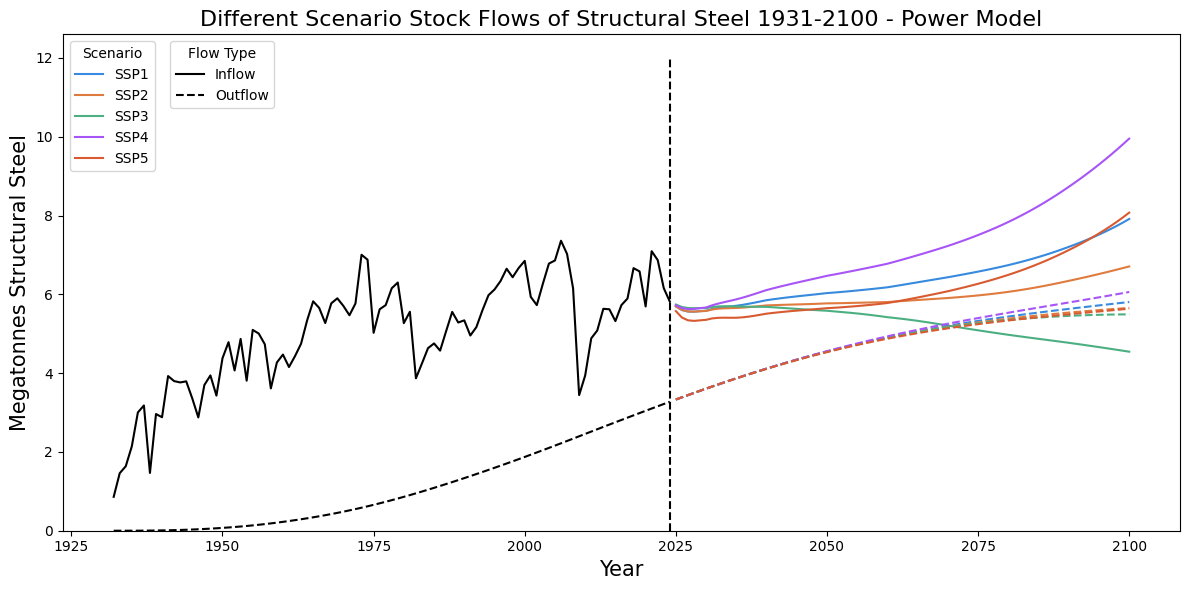

In [15]:
fig, ax = plt.subplots(figsize = (12,6))


ax.plot(steel_DSM_ssp1.t[:93], steel_DSM_ssp1.i[:93], color = 'black')
ax.plot(steel_DSM_ssp1.t[93:], steel_DSM_ssp1.i[93:], color = '#378ADD')
ax.plot(steel_DSM_ssp2.t[93:], steel_DSM_ssp2.i[93:], color = '#E07B3F')
ax.plot(steel_DSM_ssp3.t[93:], steel_DSM_ssp3.i[93:], color = '#4CAF82')
ax.plot(steel_DSM_ssp4.t[93:], steel_DSM_ssp4.i[93:], color = '#A855F7')
ax.plot(steel_DSM_ssp5.t[93:], steel_DSM_ssp5.i[93:], color = '#D85A30')
ax.plot(steel_DSM_ssp1.t[:93], steel_DSM_ssp1.o[:93], color = 'black', ls = "--")
ax.plot(steel_DSM_ssp1.t[93:], steel_DSM_ssp1.o[93:], color = '#378ADD', ls = "--")
ax.plot(steel_DSM_ssp2.t[93:], steel_DSM_ssp2.o[93:], color = '#E07B3F', ls = "--")
ax.plot(steel_DSM_ssp3.t[93:], steel_DSM_ssp3.o[93:], color = '#4CAF82', ls = "--")
ax.plot(steel_DSM_ssp4.t[93:], steel_DSM_ssp4.o[93:], color = '#A855F7', ls = "--")
ax.plot(steel_DSM_ssp5.t[93:], steel_DSM_ssp5.o[93:], color = '#D85A30', ls = "--")
ax.plot([2024,2024],[0,12], color = 'k', linestyle = '--')
plt.xlabel('Year', fontsize = 15)
plt.ylabel('Megatonnes Structural Steel',fontsize = 15)
plt.title('Different Scenario Stock Flows of Structural Steel 1931-2100 - Power Model', fontsize = 16)
scenario_handles = [
    mlines.Line2D([], [], color='#378ADD',        linestyle='-', label='SSP1'),
    mlines.Line2D([], [], color='#E07B3F', linestyle='-', label='SSP2'),
    mlines.Line2D([], [], color='#4CAF82',      linestyle='-', label='SSP3'),
    mlines.Line2D([], [], color='#A855F7',      linestyle='-', label='SSP4'),
    mlines.Line2D([], [], color='#D85A30',         linestyle='-', label='SSP5'),
]

leg1 = ax.legend(handles=scenario_handles, title='Scenario', loc='upper left')
ax.add_artist(leg1)

inflow_line = mlines.Line2D([], [], color='black', linestyle='-', label='Inflow')
outflow_line = mlines.Line2D([], [], color='black', linestyle='--', label='Outflow')

flow_handles = [
    mlines.Line2D([], [], color='black', linestyle='-',  label='Inflow'),
    mlines.Line2D([], [], color='black', linestyle='--', label='Outflow'),
]

ax.set_ylim(0,)
ax.legend(handles=flow_handles, title='Flow Type', loc='upper left', bbox_to_anchor = (0.09,1))
plt.show()

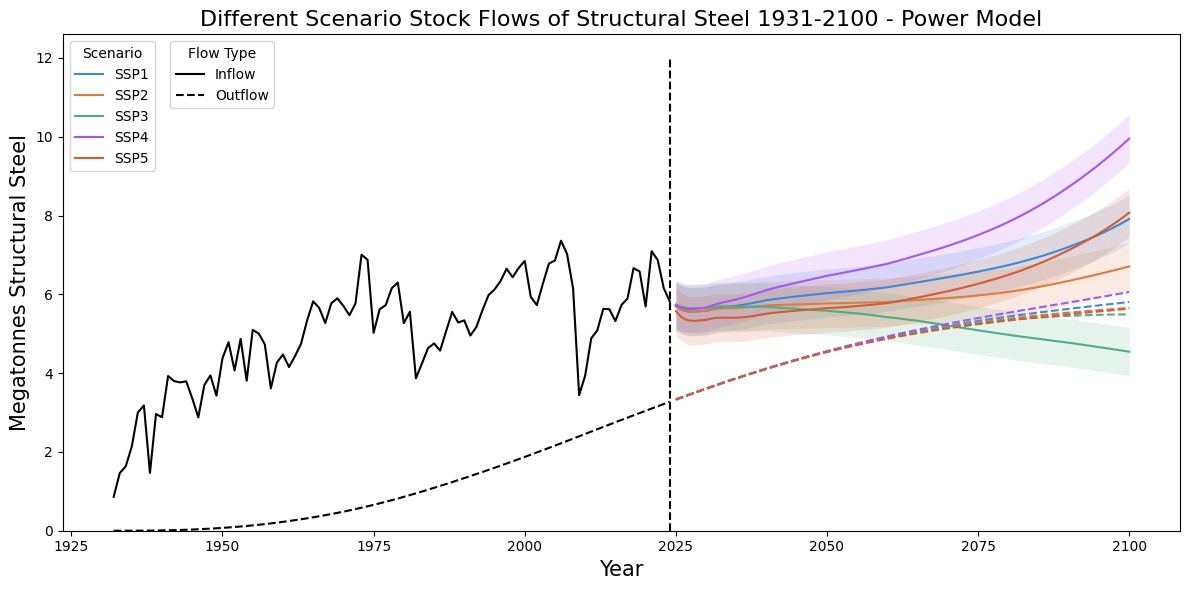

In [24]:
### Forecast with MAE bands ###

fig, ax = plt.subplots(figsize=(12,6))

ax.plot(steel_DSM_ssp1.t[:93], steel_DSM_ssp1.i[:93], color='black')
ax.plot(steel_DSM_ssp1.t[93:], steel_DSM_ssp1.i[93:], color='#378ADD')
ax.plot(steel_DSM_ssp2.t[93:], steel_DSM_ssp2.i[93:], color='#E07B3F')
ax.plot(steel_DSM_ssp3.t[93:], steel_DSM_ssp3.i[93:], color='#4CAF82')
ax.plot(steel_DSM_ssp4.t[93:], steel_DSM_ssp4.i[93:], color='#A855F7')
ax.plot(steel_DSM_ssp5.t[93:], steel_DSM_ssp5.i[93:], color='#D85A30')

ax.plot(steel_DSM_ssp1.t[:93], steel_DSM_ssp1.o[:93], color='black', ls="--")
ax.plot(steel_DSM_ssp1.t[93:], steel_DSM_ssp1.o[93:], color='#378ADD', ls="--")
ax.plot(steel_DSM_ssp2.t[93:], steel_DSM_ssp2.o[93:], color='#E07B3F', ls="--")
ax.plot(steel_DSM_ssp3.t[93:], steel_DSM_ssp3.o[93:], color='#4CAF82', ls="--")
ax.plot(steel_DSM_ssp4.t[93:], steel_DSM_ssp4.o[93:], color='#A855F7', ls="--")
ax.plot(steel_DSM_ssp5.t[93:], steel_DSM_ssp5.o[93:], color='#D85A30', ls="--")

# --- fill_between bands around each inflow line (±0.610) ---
# ax.fill_between(steel_DSM_ssp1.t[:93],
#                  steel_DSM_ssp1.i[:93] - 0.610, steel_DSM_ssp1.i[:93] + 0.610,
#                  color='black', alpha=0.15, linewidth=0)
ax.fill_between(steel_DSM_ssp1.t[93:],
                 steel_DSM_ssp1.i[93:] - 0.610, steel_DSM_ssp1.i[93:] + 0.610,
                 color='#378ADD', alpha=0.15, linewidth=0)
ax.fill_between(steel_DSM_ssp2.t[93:],
                 steel_DSM_ssp2.i[93:] - 0.610, steel_DSM_ssp2.i[93:] + 0.610,
                 color='#E07B3F', alpha=0.15, linewidth=0)
ax.fill_between(steel_DSM_ssp3.t[93:],
                 steel_DSM_ssp3.i[93:] - 0.610, steel_DSM_ssp3.i[93:] + 0.610,
                 color='#4CAF82', alpha=0.15, linewidth=0)
ax.fill_between(steel_DSM_ssp4.t[93:],
                 steel_DSM_ssp4.i[93:] - 0.610, steel_DSM_ssp4.i[93:] + 0.610,
                 color='#A855F7', alpha=0.15, linewidth=0)
ax.fill_between(steel_DSM_ssp5.t[93:],
                 steel_DSM_ssp5.i[93:] - 0.610, steel_DSM_ssp5.i[93:] + 0.610,
                 color='#D85A30', alpha=0.15, linewidth=0)

ax.plot([2024,2024],[0,12], color='k', linestyle='--')
plt.xlabel('Year', fontsize=15)
plt.ylabel('Megatonnes Structural Steel', fontsize=15)
plt.title('Different Scenario Stock Flows of Structural Steel 1931-2100 - Power Model', fontsize=16)

scenario_handles = [
    mlines.Line2D([], [], color='#378ADD', linestyle='-', label='SSP1'),
    mlines.Line2D([], [], color='#E07B3F', linestyle='-', label='SSP2'),
    mlines.Line2D([], [], color='#4CAF82', linestyle='-', label='SSP3'),
    mlines.Line2D([], [], color='#A855F7', linestyle='-', label='SSP4'),
    mlines.Line2D([], [], color='#D85A30', linestyle='-', label='SSP5'),
]

leg1 = ax.legend(handles=scenario_handles, title='Scenario', loc='upper left')
ax.add_artist(leg1)

flow_handles = [
    mlines.Line2D([], [], color='black', linestyle='-', label='Inflow'),
    mlines.Line2D([], [], color='black', linestyle='--', label='Outflow'),
]

ax.set_ylim(0,)
ax.legend(handles=flow_handles, title='Flow Type', loc='upper left', bbox_to_anchor=(0.09, 1))
plt.show()

In [17]:
start_year = 1931
n_years = len(steel_DSM_ssp1.t)
years = np.arange(start_year, start_year + n_years)

# Build all SSP flow dataframes
flow_dfs = {}

for s in range(1, 6):   # SSP1–SSP5
    model = globals()[f"steel_DSM_ssp{s}"]   # get steel_DSM_ssp1, etc.

    df = pd.DataFrame({
        f"inflow_ssp{s}":  model.i,
        f"outflow_ssp{s}": model.o,
    }, index=years)

    df.index.name = "Year"

    flow_dfs[f"ssp{s}"] = df

all_flows = pd.concat(flow_dfs.values(), axis=1)

In [18]:
all_flows.loc[2024]

inflow_ssp1     5.693083
outflow_ssp1    3.329969
inflow_ssp2     5.694787
outflow_ssp2    3.329969
inflow_ssp3     5.741518
outflow_ssp3    3.329969
inflow_ssp4     5.722451
outflow_ssp4    3.329969
inflow_ssp5     5.574647
outflow_ssp5    3.329968
Name: 2024, dtype: float64

Deconstruction / demolition emissions excluded, assumed to be the same for this. However, future versions of this model should note that deconstruction seemingly tends to have lower emissions associated with it

In [19]:
# total_flows['flows delta'] = total_flows['Total Inflow'] - total_flows['Total Outflow']
# total_flows['demand percentage'] = total_flows['Total Outflow'] / total_flows['Total Inflow']

In [20]:
all_flows['demand percentage_ssp1'] = all_flows['outflow_ssp1'] / all_flows['inflow_ssp1']
all_flows['demand percentage_ssp2'] = all_flows['outflow_ssp2'] / all_flows['inflow_ssp2']
all_flows['demand percentage_ssp3'] = all_flows['outflow_ssp3'] / all_flows['inflow_ssp3']
all_flows['demand percentage_ssp4'] = all_flows['outflow_ssp4'] / all_flows['inflow_ssp4']
all_flows['demand percentage_ssp5'] = all_flows['outflow_ssp5'] / all_flows['inflow_ssp5']


In [21]:
all_flows

,inflow_ssp1,outflow_ssp1,inflow_ssp2,outflow_ssp2,inflow_ssp3,outflow_ssp3,inflow_ssp4,outflow_ssp4,inflow_ssp5,outflow_ssp5,demand percentage_ssp1,demand percentage_ssp2,demand percentage_ssp3,demand percentage_ssp4,demand percentage_ssp5
Year,,,,,,,,,,,,,,,
1931,0.860000,0.000000,0.860000,0.000000,0.860000,0.000000,0.860000,0.000000,0.860000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1932,1.460000,0.000039,1.460000,0.000039,1.460000,0.000039,1.460000,0.000039,1.460000,0.000039,0.000027,0.000027,0.000027,0.000027,0.000027
1933,1.637000,0.000214,1.637000,0.000214,1.637000,0.000214,1.637000,0.000214,1.637000,0.000214,0.000131,0.000131,0.000131,0.000131,0.000131
1934,2.142000,0.000602,2.142000,0.000602,2.142000,0.000602,2.142000,0.000602,2.142000,0.000602,0.000281,0.000281,0.000281,0.000281,0.000281
1935,3.002000,0.001272,3.002000,0.001272,3.002000,0.001272,3.002000,0.001272,3.002000,0.001272,0.000424,0.000424,0.000424,0.000424,0.000424
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2095,7.588673,5.736747,6.553331,5.611504,4.637745,5.483953,9.419826,5.950640,7.641098,5.579294,0.755962,0.856283,1.182461,0.631714,0.730169
2096,7.663736,5.754009,6.591074,5.622904,4.614733,5.486792,9.547424,5.977531,7.741601,5.593412,0.750810,0.853109,1.188973,0.626088,0.722514
2097,7.742694,5.771233,6.629498,5.634088,4.591481,5.489025,9.678808,6.004698,7.847008,5.607589,0.745378,0.849851,1.195480,0.620396,0.714615


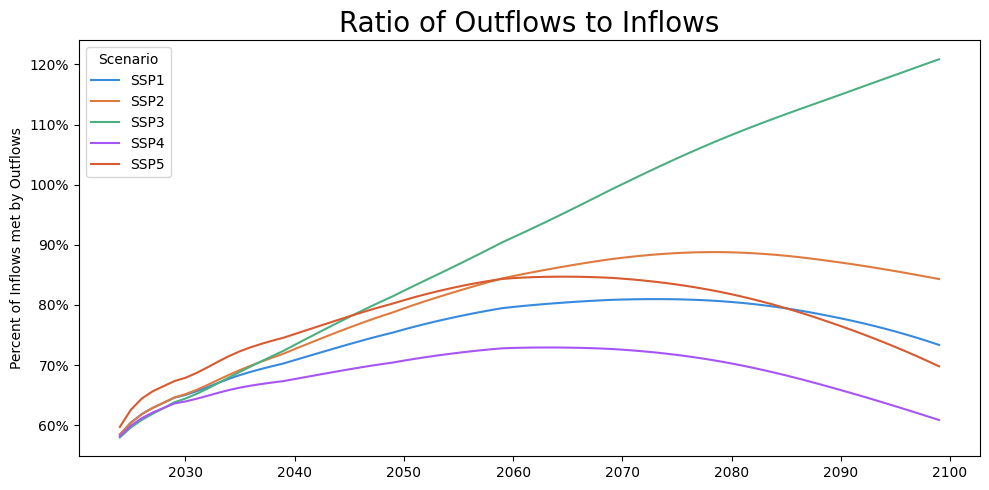

In [22]:
fig,ax = plt.subplots(figsize = (10,5))

years = all_flows.loc[2024:2100].index
ax.plot(years, all_flows['demand percentage_ssp1'].loc[2024:2100], color = '#378ADD')
ax.plot(years, all_flows['demand percentage_ssp2'].loc[2024:2100], color = '#E07B3F')
ax.plot(years, all_flows['demand percentage_ssp3'].loc[2024:2100], color = '#4CAF82')
ax.plot(years, all_flows['demand percentage_ssp4'].loc[2024:2100], color = '#A855F7')
ax.plot(years, all_flows['demand percentage_ssp5'].loc[2024:2100], color = '#D85A30')

plt.ylabel('Percent of Inflows met by Outflows')
plt.title('Ratio of Outflows to Inflows', fontsize = 20)
scenario_handles = [
    mlines.Line2D([], [], color='#378ADD',        linestyle='-', label='SSP1'),
    mlines.Line2D([], [], color='#E07B3F',       linestyle='-', label='SSP2'),
    mlines.Line2D([], [], color='#4CAF82',      linestyle='-', label='SSP3'),
    mlines.Line2D([], [], color='#A855F7',      linestyle='-', label='SSP4'),
    mlines.Line2D([], [], color='#D85A30',         linestyle='-', label='SSP5'),
]

ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.legend(handles=scenario_handles, title='Scenario', loc='upper left')

## Make simple sankey for 2019

In [23]:
df_recycling

NameError: name 'df_recycling' is not defined

In [ ]:
df_steel

,total-production,structural-total
1931,23536.93607,2396.48
1932,12411.20919,1263.68
1933,21075.74094,2145.89
1934,23636.72651,2406.64
1935,30928.68612,3149.10
...,...,...
2019,87300.00000,8888.71
2020,73500.00000,7483.62
2021,85900.00000,8746.17
2022,81200.00000,8267.62


In [ ]:
outflow = all_flows['outflow_ssp1'].loc[2019]*.98
waste = all_flows['outflow_ssp1'].loc[2019]*.02
inflow = all_flows['inflow_ssp1'].loc[2019]
scrap = df_recycling['scrap'].loc[2019]+df_recycling['Exports'].loc[2019]-df_recycling['Imports'].loc[2019] - outflow
virgin = 32000
other_use = scrap + virgin - inflow
inflow_reuse = inflow - outflow
other_reuse = scrap + virgin - inflow_reuse

In [ ]:
outflow

np.float64(4335.319203568618)

In [ ]:
import plotly.io as pio
pio.renderers.default = "browser"

In [ ]:
fig = go.Figure(go.Sankey(
    arrangement = "snap",
    node = {
        'label': ["Virgin", " Scrap", 'Feedstock', "EAF Processing","Fabrication","Built Environment","Construction Scrap", "Waste", "Other Use"],
        # 'x' : [0.1, 0.1, 0.3, 0.5, 0.7, 0.8, 0.8, 0.7],
        # 'y' : [0.7, 0.5, 0.5, 0.4, 0.4, 0.3, 0.5, 0.7]
    },
    link = {
        "source" : [0,1,2,3,4,5,5,6,2],
        "target" : [2,2,3,4,5,6,7,1,8],
        "value" : [virgin,scrap,inflow,inflow,inflow,outflow,waste,outflow,other_use]
    }

))

fig.show()

In [ ]:
fig = go.Figure(go.Sankey(
    arrangement = "snap",
    node = {
        'label': ["Virgin", " Scrap", 'Feedstock', "EAF Processing","Fabrication","Built Environment","structural Steel Scrap", "Waste", "Other Use"],
        # 'x' : [0.1, 0.1, 0.3, 0.5, 0.7, 0.8, 0.8, 0.7],
        # 'y' : [0.7, 0.5, 0.5, 0.4, 0.4, 0.3, 0.5, 0.7]
    },
    link = {
        "source" : [0,1,2,3,4,5,5,6,2],
        "target" : [2,2,3,4,5,6,7,4,8],
        "value" : [virgin,scrap,inflow_reuse,inflow_reuse,inflow,outflow,waste,outflow,other_reuse]
    }

))

fig.show()

## Brief Annual LCA

In [ ]:
production_co2 = (.898 + ((0.026+0.0824)*1.0771))*1e6
fabrication_co2 = ((0.0262+0.0824)*1.0771)*1e6

In [ ]:
flows = all_flows.loc[2024:2100]

# Find all ssp suffixes present (ssp1, ssp2, ...) based on inflow_ column names
ssp_names = sorted({col.replace('inflow_', '') for col in flows.columns if col.startswith('inflow_')})

emissions = pd.DataFrame(index=flows.index)

for ssp in ssp_names:
    inflow = flows[f'inflow_{ssp}']
    outflow = flows[f'outflow_{ssp}']
    
    # Typical (virgin) steel production emissions
    emissions[f'typical_co2_{ssp}'] = inflow * production_co2
    
    # Reused steel emissions: outflow fabricated + remainder produced new
    emissions[f'reused_co2_{ssp}'] = (outflow * fabrication_co2) + ((inflow - outflow) * production_co2)


emissions = emissions/1e3

emissions

,typical_co2_ssp1,reused_co2_ssp1,typical_co2_ssp2,reused_co2_ssp2,typical_co2_ssp3,reused_co2_ssp3,typical_co2_ssp4,reused_co2_ssp4,typical_co2_ssp5,reused_co2_ssp5
Year,,,,,,,,,,
2024,5.777099,2.787505,5.778828,2.789234,5.826249,2.836654,5.806901,2.817306,5.656915,2.667322
2025,5.684040,2.643994,5.687038,2.646993,5.762652,2.722603,5.734193,2.694146,5.491999,2.451962
2026,5.645626,2.555528,5.648917,2.558818,5.736041,2.645929,5.708306,2.618199,5.419677,2.329612
2027,5.641842,2.502127,5.644136,2.504420,5.731480,2.591730,5.712631,2.572895,5.405178,2.265547
2028,5.654468,2.465603,5.654145,2.465278,5.734983,2.546052,5.731802,2.542894,5.418868,2.230170
...,...,...,...,...,...,...,...,...,...,...
2095,7.700664,2.550301,6.650042,1.612121,4.706187,-0.217222,9.558840,4.216447,7.753863,2.744859
2096,7.776834,2.610974,6.688342,1.640186,4.682836,-0.243122,9.688321,4.321786,7.855849,2.834170
2097,7.856958,2.675634,6.727334,1.669136,4.659241,-0.268721,9.821644,4.430719,7.962811,2.928404


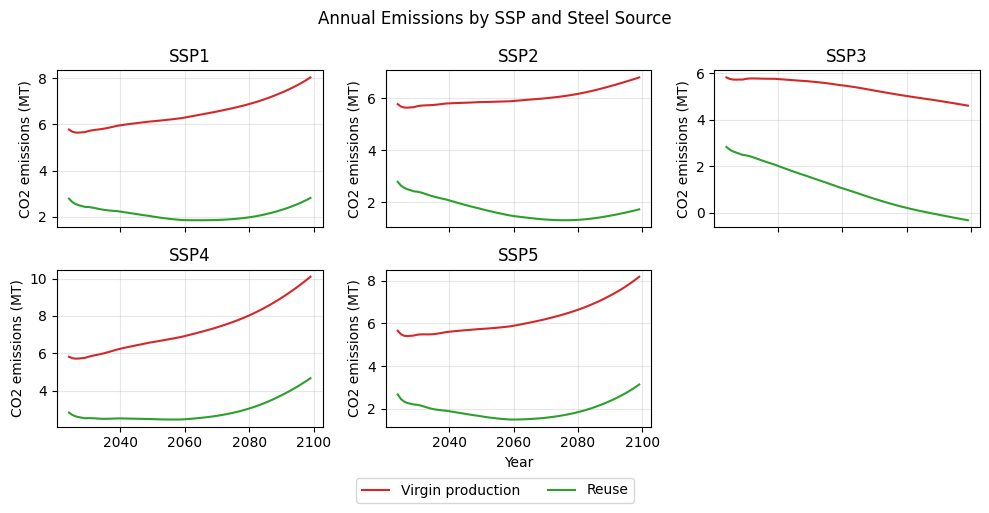

In [ ]:

fig, axes = plt.subplots(2, 3, figsize=(10, 5), sharex=True)
axes = axes.flatten()

for ax, ssp in zip(axes, ssp_names):
    ax.plot(emissions.index, emissions[f'typical_co2_{ssp}'], label='Virgin production', color='#d62728')
    ax.plot(emissions.index, emissions[f'reused_co2_{ssp}'], label='Reuse', color='#2ca02c')
    ax.set_title(ssp.upper())
    ax.set_ylabel('CO2 emissions (MT)')
    ax.grid(alpha=0.3)

# Hide any unused subplot(s) — e.g. if you have 5 SSPs in a 6-slot grid
for ax in axes[len(ssp_names):]:
    ax.axis('off')

# Shared legend, built from the first panel's lines
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.02), fontsize=10)
fig.suptitle('Annual Emissions by SSP and Steel Source')

for ax in axes[-2:]:
    if ax.get_visible():
        ax.set_xlabel('Year')

plt.tight_layout(rect=[0, 0.03, 1, 1])  # leave room at bottom for legend
plt.savefig('emissions_by_ssp.png', dpi=150, bbox_inches='tight')
plt.show()